In [148]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [149]:
df = pd.read_csv(r"D:\new\OneDrive\Desktop\used_cars\used_car_listings_dataset_from_hatla2ee2026.csv")

In [150]:
df.shape

(13652, 8)

In [151]:
df.dropna(inplace=True)

In [152]:
df.info()

<class 'pandas.DataFrame'>
Index: 13551 entries, 0 to 13651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         13551 non-null  str    
 1   model         13551 non-null  str    
 2   year          13551 non-null  float64
 3   km            13551 non-null  str    
 4   fuel          13551 non-null  str    
 5   transmission  13551 non-null  str    
 6   price         13551 non-null  str    
 7   description   13551 non-null  str    
dtypes: float64(1), str(7)
memory usage: 1.7 MB


In [153]:
df

,brand,model,year,km,fuel,transmission,price,description
0,Kia,Rio,2013.0,"122,000 KM",Gas,Automatic,"530,000 EGP",Kia Rio 2013
1,Chevrolet,Aveo,2017.0,"2,017 KM",Gas,Automatic,"395,000 EGP",Chevrolet Aveo 2017
2,Hyundai,Matrix,2006.0,"260,000 KM",Diesel,Automatic,"410,000 EGP",Hyundai Matrix 2006
3,Nissan,Qashqai,2025.0,"50,000 KM",Gas,Automatic,"1,320,000 EGP",Nissan Qashqai 2025
4,Daewoo,Lanos 2,2006.0,"260,000 KM",Gas,Manual,"255,000 EGP",Daewoo Lanos 2 2006
...,...,...,...,...,...,...,...,...
13647,Audi,Q8,2025.0,0 KM,Gas,Automatic,"6,650,000 EGP",Audi Q8 2025
13648,Opel,Astra,2017.0,"200,000 KM",Gas,Automatic,"580,000 EGP",Opel Astra 2017
13649,Suzuki,S Presso,2020.0,0 KM,Gas,Manual,"150,000 EGP",Suzuki S Presso 2020
13650,Nissan,Qashqai,2021.0,"65,000 KM",Gas,Automatic,"1,020,000 EGP",Nissan Qashqai 2021


In [154]:
df['price'] = df['price'].str.replace('EGP', '', regex=False).str.replace(',', '', regex=False).str.strip()


In [155]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

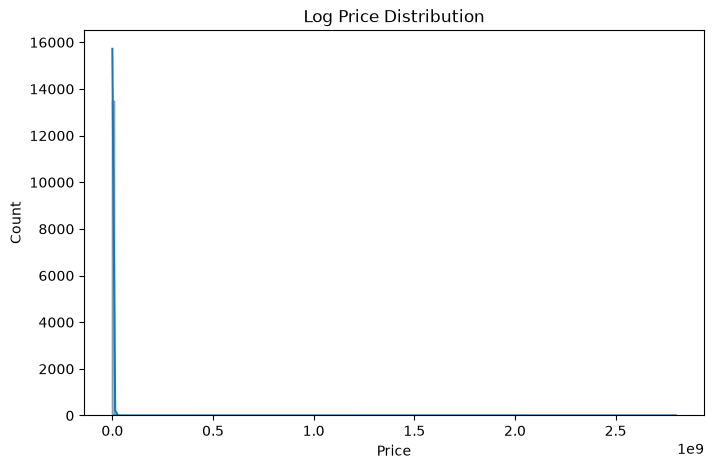

In [156]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Log Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [157]:
df[['price']].describe()

,price
count,1.355100e+04
mean,1.496623e+06
std,2.560178e+07
min,2.000000e+04
25%,4.000000e+05
50%,7.000000e+05
75%,1.350000e+06
max,2.800000e+09


In [158]:
df['price']

0         530000
1         395000
2         410000
3        1320000
4         255000
          ...   
13647    6650000
13648     580000
13649     150000
13650    1020000
13651     565000
Name: price, Length: 13551, dtype: int64

In [159]:
df['km'] = df['km'].str.replace('KM', '', regex=False).str.replace(',', '', regex=False).str.strip()


In [160]:
df['km'] = pd.to_numeric(df['km'], errors='coerce')

In [161]:
df['km'].info()

<class 'pandas.Series'>
Index: 13551 entries, 0 to 13651
Series name: km
Non-Null Count  Dtype
--------------  -----
13551 non-null  int64
dtypes: int64(1)
memory usage: 211.7 KB


In [162]:
df.drop(df[df['km']==0].index, inplace=True)

In [163]:
df.sort_values(by='price', ascending=True).head(30)

,brand,model,year,km,fuel,transmission,price,description
9818,Fiat,127,1985.0,80000,Gas,Manual,28000,Fiat 127 1985
9033,Suzuki,Van,2017.0,932653,Gas,Manual,30000,Suzuki Van 2017
2340,Chevrolet,T-Series,2005.0,150000,Diesel,Manual,30000,Chevrolet T-Series 2005
8830,Fiat,Siena,2001.0,43000,Gas,Manual,35000,Fiat Siena 2001
3910,Seat,133,1981.0,1000,Gas,Automatic,37000,Seat 133 1981
8386,Fiat,127,1987.0,100000,Gas,Manual,38000,Fiat 127 1987
2098,Fiat,127,1983.0,100000,Gas,Manual,38000,Fiat 127 1983
2777,Fiat,128,1982.0,100000,Gas,Manual,39000,Fiat 128 1982
6375,Fiat,127,1985.0,500000,Gas,Manual,40000,Fiat 127 1985
9414,Fiat,128,1987.0,25000,Gas,Manual,40000,Fiat 128 1987


In [164]:
df['brand'].unique()

<ArrowStringArray>
[        'Kia',   'Chevrolet',     'Hyundai',      'Nissan',      'Daewoo',
     'Renault',    'Daihatsu',    'Mercedes',      'Subaru',        'Lada',
  'Brilliance',     'Citroën',         'BMW',  'Volkswagen',      'Suzuki',
     'Peugeot',  'Mitsubishi',        'Opel',       'Chery',      'Toyota',
        'Fiat',          'MG',       'Skoda',       'Geely',        'Mini',
        'Audi',      'Jetour',         'Jac',    'Speranza',       'Mazda',
     'Emgrand',        'Jeep',      'Senova',        'Seat',        'Alfa',
      'Canghe',        'Ford',        'Baic',       'Honda',        'DFSK',
         'Byd',      'Proton',        'Land',     'Porsche',       'Smart',
       'Saipa',       'Volvo',         'Gmc',    'Chrysler',       'Karry',
       'Aston',   'Slingshot',       'Ssang',       'Great',       'Tesla',
       'Zotye',       'Isuzu',     'Bestune',     'Changan',       'Haval',
       'Avatr',       'Rolls',       'Kenbo',      'Jaguar',       'H

In [165]:
top_20_brands = (
    df.groupby('brand')['model']
    .nunique()
    .sort_values(ascending=False)
    .head(20)
)

print(top_20_brands)

brand
Mercedes      88
BMW           54
Hyundai       41
Fiat          35
Volkswagen    28
Kia           25
Renault       25
Peugeot       23
Toyota        23
Geely         19
Chevrolet     19
Suzuki        17
Mitsubishi    17
Skoda         16
Citroën       16
Chery         15
Jeep          14
MG            13
Daewoo        12
Changan       12
Name: model, dtype: int64


In [166]:
df=df[df['brand'].isin(top_20_brands.index)]

In [167]:
len(df)

7559

In [168]:
df['year'] = df['year'].astype(int)

In [169]:
df['year'].head()

0    2013
1    2017
2    2006
4    2006
6    2015
Name: year, dtype: int64

In [170]:
df['brand'].value_counts()

brand
Hyundai       917
Mercedes      794
Kia           769
Renault       656
Chevrolet     528
BMW           509
Toyota        382
Peugeot       369
Fiat          352
Skoda         349
Mitsubishi    327
Volkswagen    261
Chery         245
Daewoo        243
MG            236
Suzuki        186
Jeep          156
Citroën       137
Geely         104
Changan        39
Name: count, dtype: int64

In [171]:
df['fuel'].value_counts()

fuel
Gas            7038
Diesel          281
Natural Gas     140
Hybrid           61
Electric         39
Name: count, dtype: int64

In [172]:
df.drop('description', axis=1, inplace=True)

In [173]:
df

,brand,model,year,km,fuel,transmission,price
0,Kia,Rio,2013,122000,Gas,Automatic,530000
1,Chevrolet,Aveo,2017,2017,Gas,Automatic,395000
2,Hyundai,Matrix,2006,260000,Diesel,Automatic,410000
4,Daewoo,Lanos 2,2006,260000,Gas,Manual,255000
6,Renault,Logan,2015,234000,Gas,Manual,320000
...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Gas,Manual,200000
13640,Fiat,Tempra,1997,160000,Gas,Manual,95000
13642,Fiat,Grand Punto,2015,200000,Gas,Automatic,445000
13645,Hyundai,Excel,1996,208000,Gas,Manual,160000


In [174]:
df = df[df["price"] <= 50_000_000].copy()

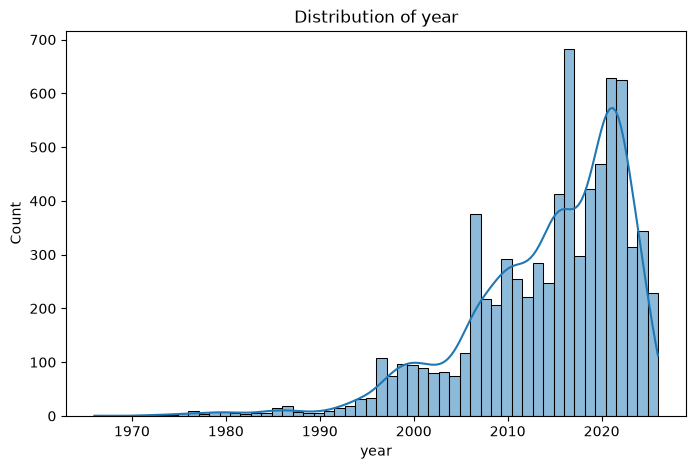

In [175]:

numeric_cols = ['year']

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.show()

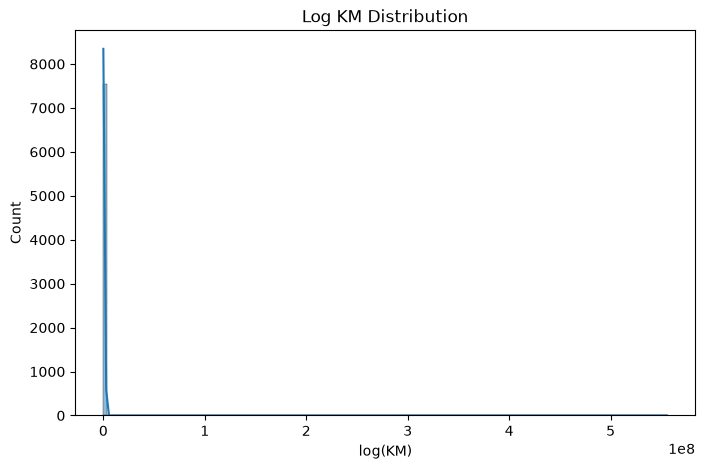

In [176]:
plt.figure(figsize=(8, 5))

sns.histplot(df['km'], kde=True)

plt.title('Log KM Distribution')
plt.xlabel('log(KM)')
plt.ylabel('Count')

plt.show()

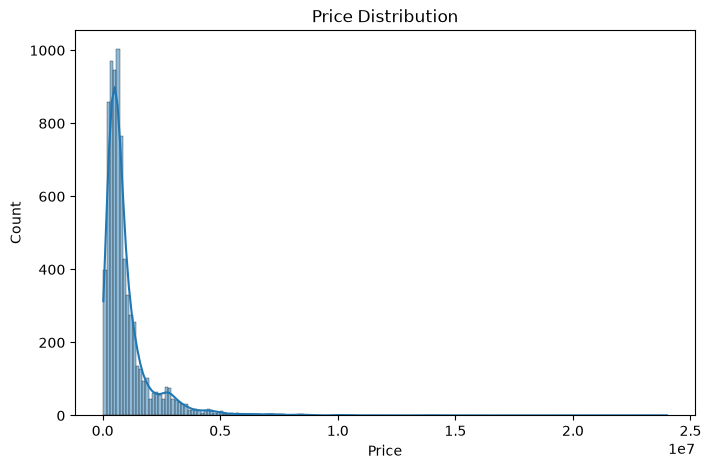

In [177]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [178]:
df['price'].describe()

count    7.558000e+03
mean     1.011145e+06
std      1.210013e+06
min      2.800000e+04
25%      4.000000e+05
50%      6.500000e+05
75%      1.100000e+06
max      2.400000e+07
Name: price, dtype: float64

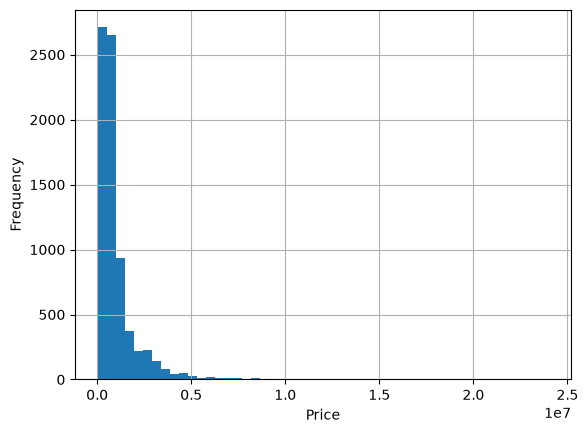

In [179]:
df['price'].hist(bins=50)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

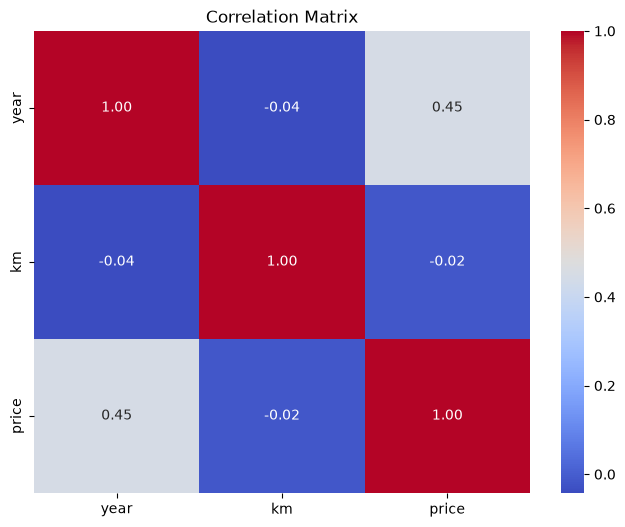

In [180]:

numeric_cols = ['year', 'km', 'price']

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [181]:
fuel_dummies = pd.get_dummies(df['fuel'], prefix='fuel', dtype=int)

df = pd.concat([df, fuel_dummies], axis=1)

df.drop('fuel', axis=1, inplace=True)

In [182]:
df['model'].value_counts()

model
Corolla     253
C 180       228
Lanos       177
Optra       169
Logan       161
           ... 
518           1
Terracan      1
124           1
Avensis       1
640           1
Name: count, Length: 498, dtype: int64

In [183]:
df

,brand,model,year,km,transmission,price,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
0,Kia,Rio,2013,122000,Automatic,530000,0,0,1,0,0
1,Chevrolet,Aveo,2017,2017,Automatic,395000,0,0,1,0,0
2,Hyundai,Matrix,2006,260000,Automatic,410000,1,0,0,0,0
4,Daewoo,Lanos 2,2006,260000,Manual,255000,0,0,1,0,0
6,Renault,Logan,2015,234000,Manual,320000,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Manual,200000,0,0,1,0,0
13640,Fiat,Tempra,1997,160000,Manual,95000,0,0,1,0,0
13642,Fiat,Grand Punto,2015,200000,Automatic,445000,0,0,1,0,0
13645,Hyundai,Excel,1996,208000,Manual,160000,0,0,1,0,0


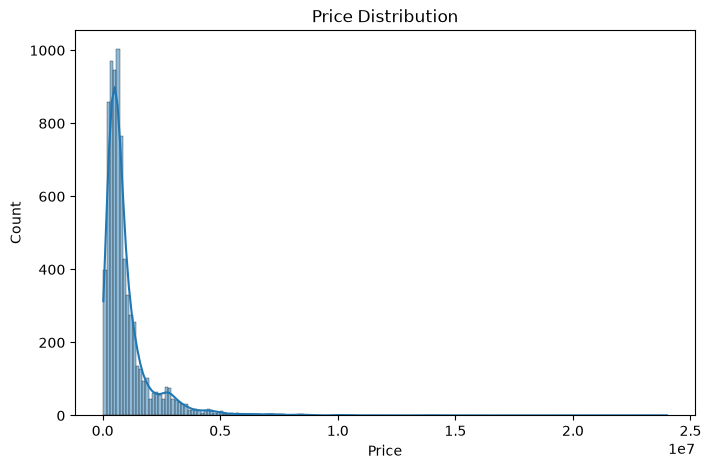

In [184]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

plt.show()

In [185]:
x=df.drop(['price'], axis=1)
y=df['price']

In [186]:
x

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
0,Kia,Rio,2013,122000,Automatic,0,0,1,0,0
1,Chevrolet,Aveo,2017,2017,Automatic,0,0,1,0,0
2,Hyundai,Matrix,2006,260000,Automatic,1,0,0,0,0
4,Daewoo,Lanos 2,2006,260000,Manual,0,0,1,0,0
6,Renault,Logan,2015,234000,Manual,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
13639,Kia,Sephia,2000,295000,Manual,0,0,1,0,0
13640,Fiat,Tempra,1997,160000,Manual,0,0,1,0,0
13642,Fiat,Grand Punto,2015,200000,Automatic,0,0,1,0,0
13645,Hyundai,Excel,1996,208000,Manual,0,0,1,0,0


In [187]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [188]:
scaler = StandardScaler()

x_train[['year', 'km']] = scaler.fit_transform(x_train[['year', 'km']])
x_test[['year', 'km']] = scaler.transform(x_test[['year', 'km']])

In [189]:
x_train["transmission"] = x_train["transmission"].map({"Manual": 0,"Automatic": 1})

x_test["transmission"] = x_test["transmission"].map({"Manual": 0,"Automatic": 1})

In [190]:
x_train

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
1392,Mercedes,C 180,-1.440894,0.001364,1,0,0,0,1,0
9559,BMW,X1,0.555358,-0.022743,1,0,0,1,0,0
10249,Citroën,C Elysee,0.203078,-0.011941,1,0,0,1,0,0
7114,Fiat,Tipo,0.907638,-0.025377,1,1,0,0,0,0
4000,Hyundai,Accent RB,0.320505,-0.016156,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
9274,Chevrolet,Aveo,0.790211,-0.028012,1,0,0,1,0,0
9343,Citroën,C4,0.203078,-0.016551,1,0,0,1,0,0
9634,Chevrolet,Aveo,-0.149201,-0.002983,0,0,0,1,0,0
1611,MG,6,0.790211,-0.022743,1,0,0,1,0,0


In [191]:
df['brand'].value_counts()

brand
Hyundai       917
Mercedes      794
Kia           769
Renault       655
Chevrolet     528
BMW           509
Toyota        382
Peugeot       369
Fiat          352
Skoda         349
Mitsubishi    327
Volkswagen    261
Chery         245
Daewoo        243
MG            236
Suzuki        186
Jeep          156
Citroën       137
Geely         104
Changan        39
Name: count, dtype: int64

In [192]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

x_train_encoded = encoder.fit_transform(x_train[['brand', 'model']])
x_test_encoded = encoder.transform(x_test[['brand', 'model']])

In [193]:
x_train2 = pd.concat([x_train.drop(columns=['brand', 'model']).reset_index(drop=True), pd.DataFrame(x_train_encoded)],axis=1)

x_test2 = pd.concat([x_test.drop(columns=['brand', 'model']).reset_index(drop=True),pd.DataFrame(x_test_encoded)],axis=1)

In [194]:
x_train

,brand,model,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas
1392,Mercedes,C 180,-1.440894,0.001364,1,0,0,0,1,0
9559,BMW,X1,0.555358,-0.022743,1,0,0,1,0,0
10249,Citroën,C Elysee,0.203078,-0.011941,1,0,0,1,0,0
7114,Fiat,Tipo,0.907638,-0.025377,1,1,0,0,0,0
4000,Hyundai,Accent RB,0.320505,-0.016156,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
9274,Chevrolet,Aveo,0.790211,-0.028012,1,0,0,1,0,0
9343,Citroën,C4,0.203078,-0.016551,1,0,0,1,0,0
9634,Chevrolet,Aveo,-0.149201,-0.002983,0,0,0,1,0,0
1611,MG,6,0.790211,-0.022743,1,0,0,1,0,0


In [195]:
x_train2

,year,km,transmission,fuel_Diesel,fuel_Electric,fuel_Gas,fuel_Hybrid,fuel_Natural Gas,0,1,...,488,489,490,491,492,493,494,495,496,497
0,-1.440894,0.001364,1,0,0,0,1,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.555358,-0.022743,1,0,0,1,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.203078,-0.011941,1,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.907638,-0.025377,1,1,0,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.320505,-0.016156,1,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6041,0.790211,-0.028012,1,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6042,0.203078,-0.016551,1,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6043,-0.149201,-0.002983,0,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6044,0.790211,-0.022743,1,0,0,1,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [196]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [197]:
model = XGBRegressor(n_estimators=500,learning_rate=0.1,max_depth=6,subsample=0.8,colsample_bytree=0.8,random_state=42)

model.fit(x_train2, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [198]:
y_pred = model.predict(x_test2)

In [199]:
mae_xgboost = mean_absolute_error(y_test, y_pred)
rmse_xgboost = mean_squared_error(y_test, y_pred) ** 0.5
r2_xgboost = r2_score(y_test, y_pred)

print("MAE:", mae_xgboost)
print("RMSE:", rmse_xgboost)
print("R2:", r2_xgboost)

MAE: 144796.375
RMSE: 385753.3729833091
R2: 0.8916350603103638


In [200]:
from catboost import CatBoostRegressor

cat_features = x_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

x_train = x_train.copy()
x_test = x_test.copy()

for col in cat_features:
    x_train[col] = x_train[col].fillna('Unknown').astype(str)
    x_test[col] = x_test[col].fillna('Unknown').astype(str)

model = CatBoostRegressor(iterations=1000,learning_rate=0.1,depth=6,loss_function='MAE',verbose=100)

model.fit(x_train, y_train, cat_features=cat_features)

predictions = model.predict(x_test)


mae_catboost =mean_absolute_error(y_test, predictions)
r2_catboost = r2_score(y_test, predictions)
print("MAE:", mae_catboost)
print("R2 Score:", r2_catboost)

0:	learn: 573533.2653359	total: 33.8ms	remaining: 33.8s
100:	learn: 212629.6305802	total: 3.48s	remaining: 31s
200:	learn: 195810.4946771	total: 6.61s	remaining: 26.3s
300:	learn: 186378.1809970	total: 9.72s	remaining: 22.6s
400:	learn: 179659.2778880	total: 12.8s	remaining: 19.1s
500:	learn: 175304.3198608	total: 16.7s	remaining: 16.6s
600:	learn: 170619.8553188	total: 20.8s	remaining: 13.8s
700:	learn: 167872.1819262	total: 24s	remaining: 10.3s
800:	learn: 165157.8980268	total: 27.1s	remaining: 6.74s
900:	learn: 162691.2165498	total: 30.3s	remaining: 3.33s
999:	learn: 160599.8674808	total: 33.6s	remaining: 0us
MAE: 184389.07999736938
R2 Score: 0.811890495968254


In [201]:
print("MAE:", mae_xgboost)
print("RMSE:", rmse_xgboost)
print("R2:", r2_xgboost)
print("------------------------------------------")
print("MAE:", mae_catboost)
print("R2 Score:", r2_catboost)

MAE: 144796.375
RMSE: 385753.3729833091
R2: 0.8916350603103638
------------------------------------------
MAE: 184389.07999736938
R2 Score: 0.811890495968254


In [203]:
# from sklearn.ensemble import (
#     RandomForestRegressor,
#     ExtraTreesRegressor,
#     AdaBoostRegressor,
#     GradientBoostingRegressor,
#     VotingRegressor,
#     StackingRegressor
# )

# from sklearn.tree import DecisionTreeRegressor
# from sklearn.linear_model import Ridge
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# import numpy as np
# import pandas as pd

In [204]:
# def evaluate_model(model, X_train, y_train, X_test, y_test):
#     model.fit(X_train, y_train)

#     y_pred = model.predict(X_test)

#     mae = mean_absolute_error(y_test, y_pred)
#     rmse = np.sqrt(mean_squared_error(y_test, y_pred))
#     r2 = r2_score(y_test, y_pred)

#     return {
#         "MAE": mae,
#         "RMSE": rmse,
#         "R2": r2
#     }

In [205]:
# x_train2.columns = x_train2.columns.astype(str)
# x_test2.columns = x_test2.columns.astype(str)
# rf = RandomForestRegressor(
#     n_estimators=200,
#     max_depth=20,
#     min_samples_split=5,
#     min_samples_leaf=2,
#     random_state=42,
#     n_jobs=-1
# )

# rf_results = evaluate_model(
#     rf, x_train2, y_train, x_test2, y_test
# )

# print(rf_results)

In [206]:
# ada = AdaBoostRegressor(
#     estimator=DecisionTreeRegressor(max_depth=4),
#     n_estimators=100,
#     learning_rate=0.05,
#     random_state=42
# )

# ada_results = evaluate_model(
#     ada, x_train2, y_train, x_test2, y_test
# )

# print(ada_results)

In [207]:
# gb = GradientBoostingRegressor(
#     n_estimators=200,
#     learning_rate=0.05,
#     max_depth=3,
#     loss="squared_error",
#     random_state=42
# )

# gb_results = evaluate_model(
#     gb, x_train2, y_train, x_test2, y_test
# )

# print(gb_results)

In [208]:
# results = pd.DataFrame({
#     "Random Forest": rf_results,
#     "AdaBoost": ada_results,
#     "Gradient Boosting": gb_results
# }).T

# results = results.sort_values("MAE")

# print(results)

In [209]:
# stack = StackingRegressor(
#     estimators=[
#         ("rf", RandomForestRegressor(n_estimators=100,max_depth=20,random_state=42,n_jobs=1)),
#         ("gb", GradientBoostingRegressor(n_estimators=100,
#             learning_rate=0.05,
#             max_depth=3,
#             random_state=42)),
#         ("ada", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3),n_estimators=50,learning_rate=0.05,random_state=42))
#     ],
#     final_estimator=Ridge(alpha=1.0),
#     cv=5,
#     n_jobs=-1
# )

# stack_results = evaluate_model(
#     stack, x_train2, y_train, x_test2, y_test
# )

# print(stack_results)